# Experiments 13A and 13B: validation parity

Longer training recovered silicon predictions with the original shared head: **13A reaches 4.20 ppm Si / 6.72 ppm O**. Balancing the loss further improves silicon to **3.22 ppm**, with oxygen worsening to **7.84 ppm**.

The plots use the **best validation checkpoints**, on the same 50 validation structures (2,400 silicon and 4,800 oxygen atoms). Experiment 12 provides the matched baseline. Neither the test split nor the raw dataset was accessed.


In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image

folder = "13-TensorNequIP-MSIsotropy-Shared-Head-Evaluation-figures"
candidates = [Path.cwd()/folder, Path.cwd()/"experiments"/folder,
              Path("/Users/louismcauliffe/code/research/NequIP_experiments/experiments")/folder]
data = next(p for p in candidates if p.is_dir())
metrics = pd.read_csv(data/"metrics.csv", dtype={"run": str})
provenance = pd.read_csv(data/"provenance.csv", dtype={"run": str})
manifest = json.loads((data/"manifest.json").read_text())
assert hashlib.sha256((data/"predictions.csv.gz").read_bytes()).hexdigest() == manifest["prediction_sha256"]
for filename, expected in manifest["files_sha256"].items():
    path = Path(filename)
    if path.exists():
        assert hashlib.sha256(path.read_bytes()).hexdigest() == expected, filename
best = metrics.query('split == "valid" and checkpoint == "best"')
display(best[["run", "element", "N", "RMSE", "MAE", "R2", "bias", "slope"]].round(4))

,run,element,N,RMSE,MAE,R2,bias,slope
0,12,O,4800,7.2264,4.6129,0.8810,0.2933,0.8360
1,12,Si,2400,9.0087,7.0853,0.0119,0.0654,0.0076
4,13A,O,4800,6.7212,4.2887,0.8971,0.3571,0.8575
5,13A,Si,2400,4.2013,3.0271,0.7851,-0.0110,0.7316
8,13B,O,4800,7.8415,4.9548,0.8599,0.4223,0.8044
9,13B,Si,2400,3.2241,2.2715,0.8734,0.0116,0.8455


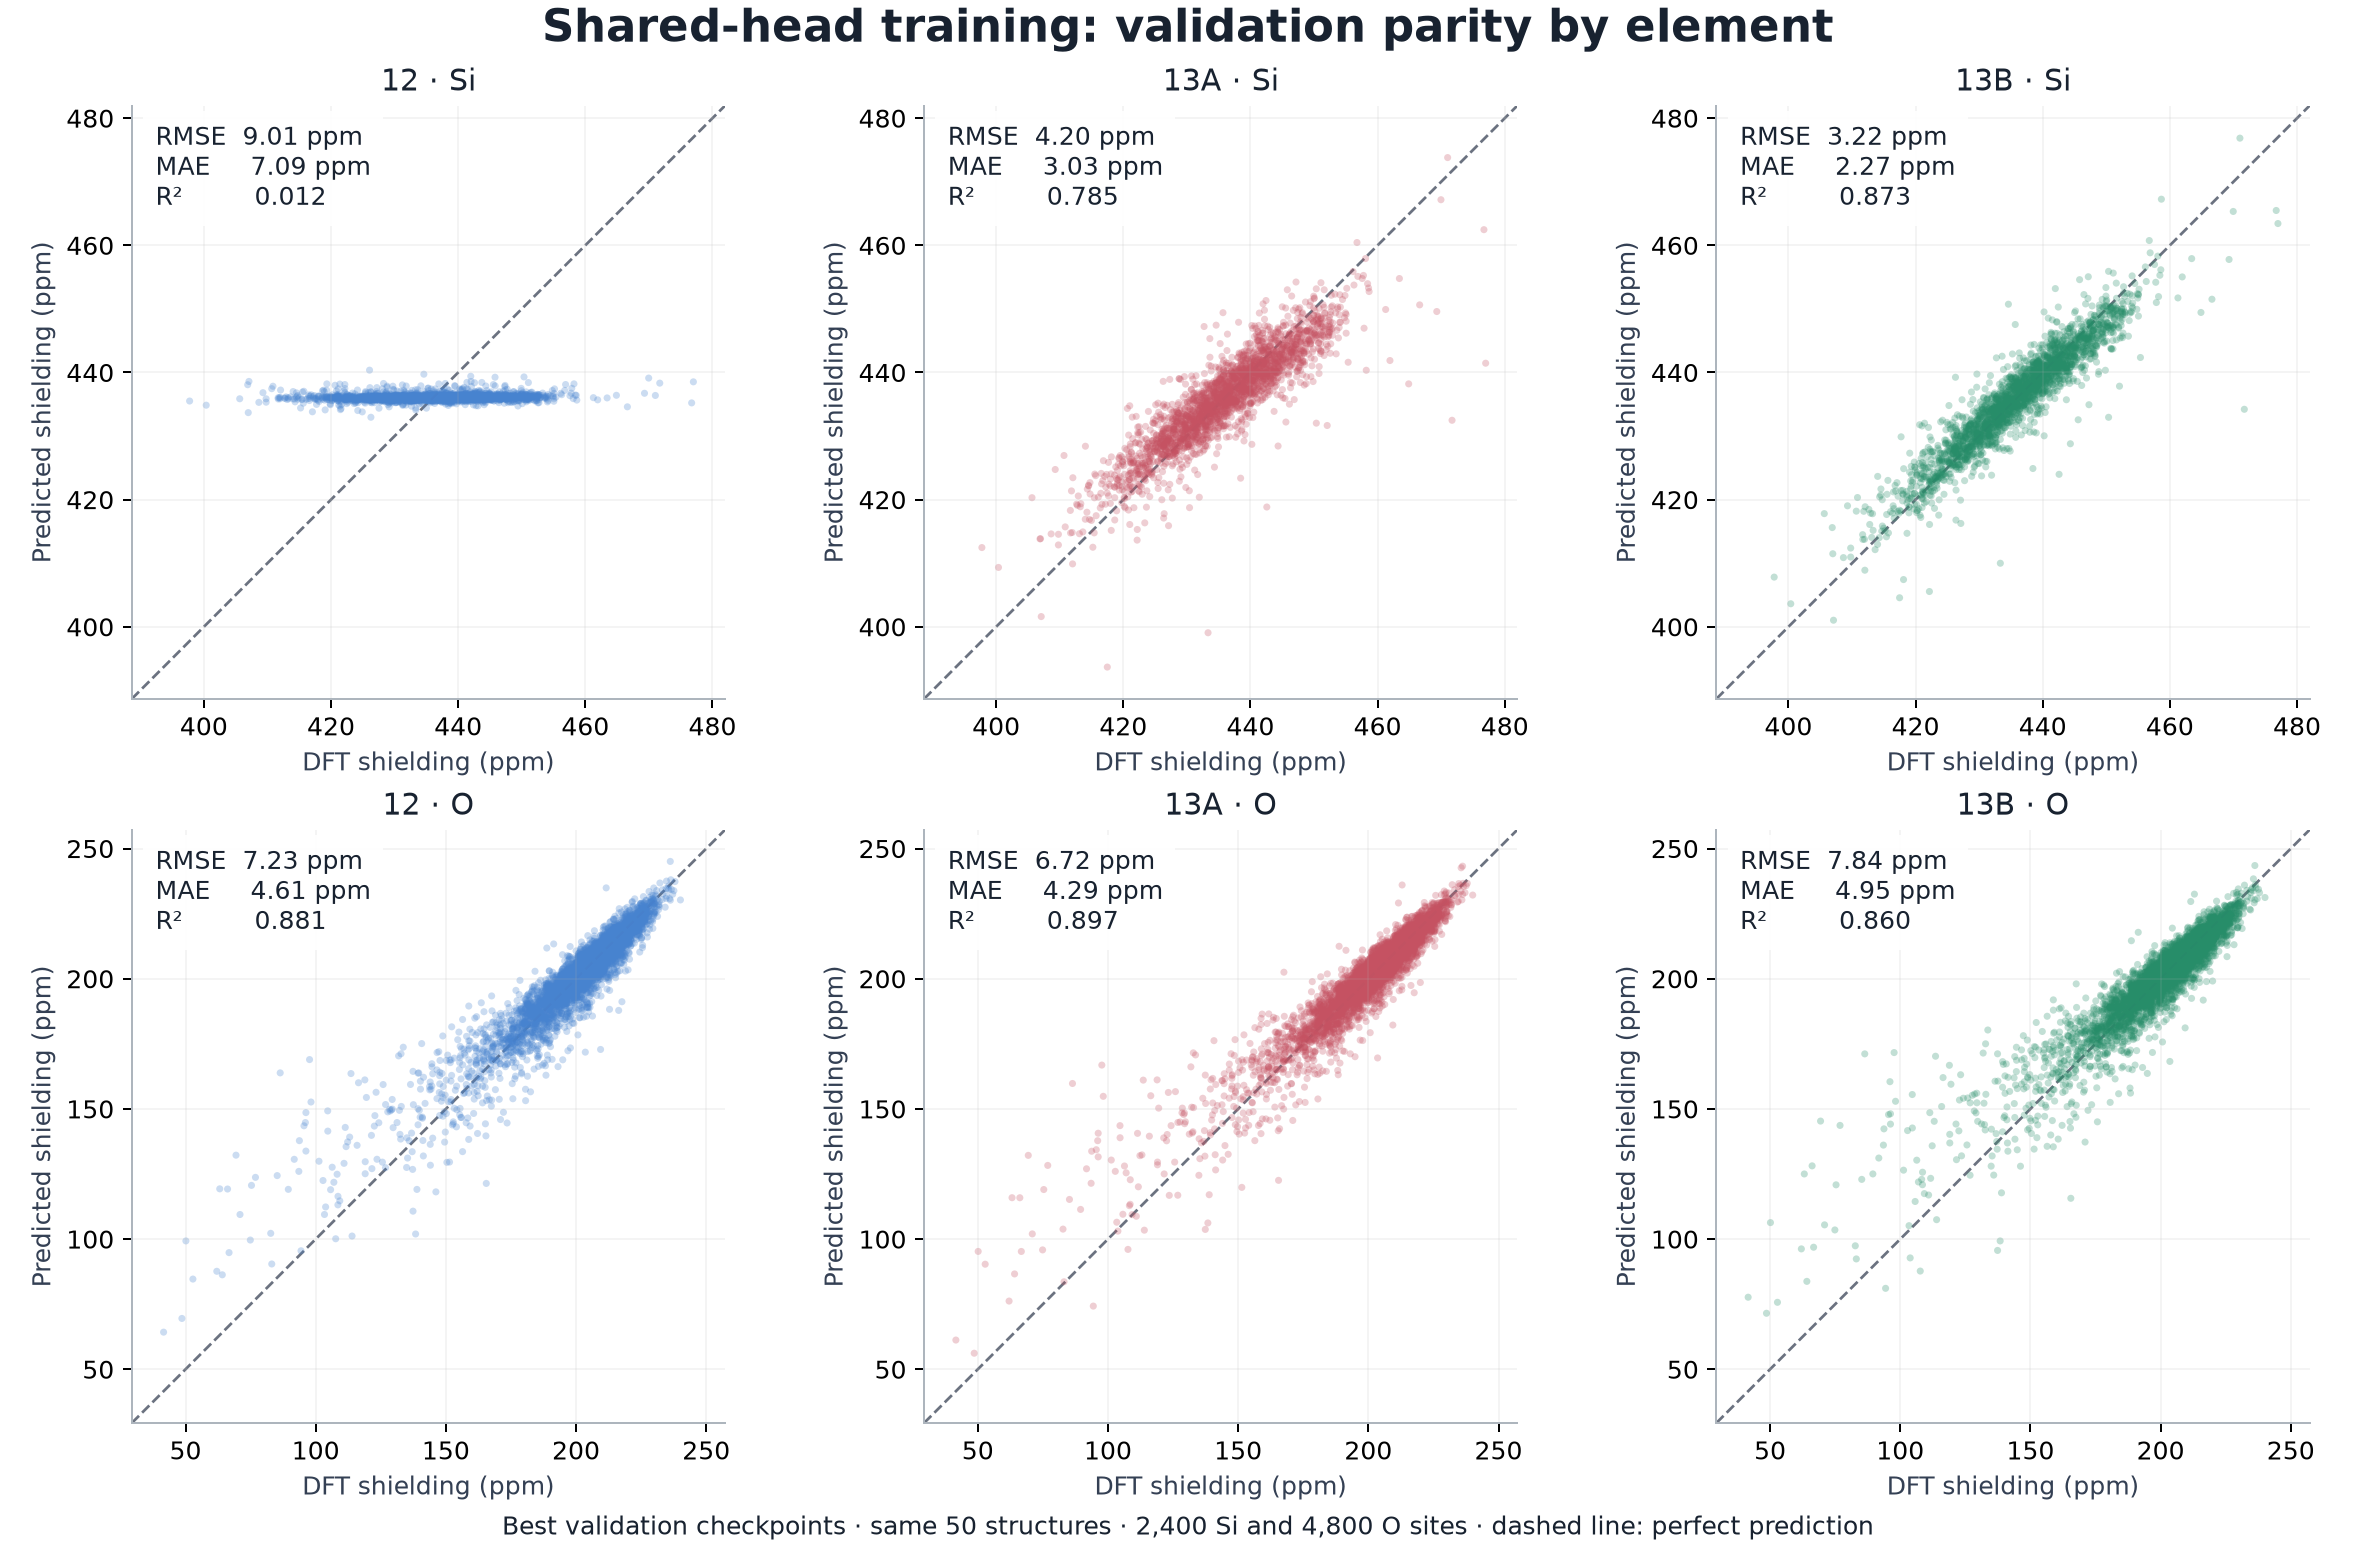

In [2]:
display(Image(filename=str(data/"validation-parity.png")))

## Reading the parity plots

- **Silicon:** experiment 12's nearly horizontal predictions are replaced by predictions that follow the DFT values in both 13A and 13B. The balanced objective produces the tighter silicon fit.
- **Oxygen:** 13A improves on experiment 12. In 13B, the oxygen cloud broadens; improving silicon has come at a cost in oxygen accuracy. Residual plots below help expose errors at the ends of the shielding range.
- **Comparison rule:** raw weighted MSE in 12/13A and normalized weighted MSE in 13B have different units and numerical scales. Compare elemental RMSE/MAE in ppm and R², rather than the numerical height of total-loss curves.


In [3]:
display(provenance[["run", "best_epoch", "last_epoch", "max_epochs", "checks_since_best",
                    "runtime_hours", "final_lr", "export_matches_best"]])
display(metrics.pivot(index=["run", "element"], columns=["split", "checkpoint"], values="RMSE").round(4))

,run,best_epoch,last_epoch,max_epochs,checks_since_best,runtime_hours,final_lr,export_matches_best
0,12,297,300,300,3,1.103412,0.003000,True
1,13A,1948,2248,3000,300,4.702352,0.000011,True
2,13B,2567,2867,3000,300,7.092634,0.000004,True


split         valid           train        
checkpoint     best    last    best    last
run element                                
12  O        7.2264  7.2564  6.8730  6.8650
    Si       9.0087  9.0058  8.7717  8.7689
13A O        6.7212  6.7257  6.3366  6.3338
    Si       4.2013  4.2022  4.0296  4.0223
13B O        7.8415  7.8474  7.3061  7.3087
    Si       3.2241  3.2252  3.0586  3.0580

## Has training settled?

13A selected epoch **1,948** and stopped at **2,248**; 13B selected epoch **2,567** and stopped at **2,867** (13B's epoch count starts from its new optimizer run). Both recorded 300 checks without a new best validation loss and reduced their learning rates substantially. Neither stopped because it reached the 3,000-epoch ceiling.

This strongly supports insufficient training as a major cause of experiment 12's silicon collapse. It does not prove a global optimum: the earlier direct-fit diagnostics still achieved lower errors, and did not reproduce AdamW's weight decay. The shared head and loss weighting also limit which Si/O trade-offs can be reached.


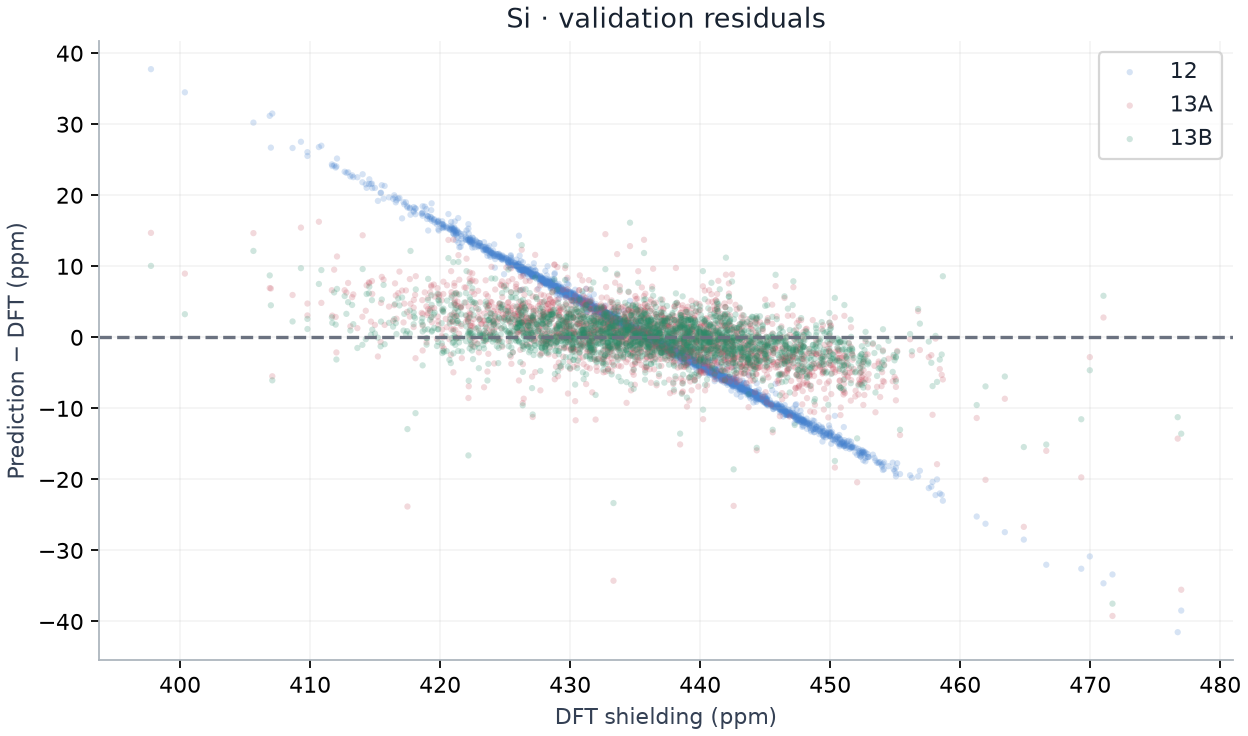

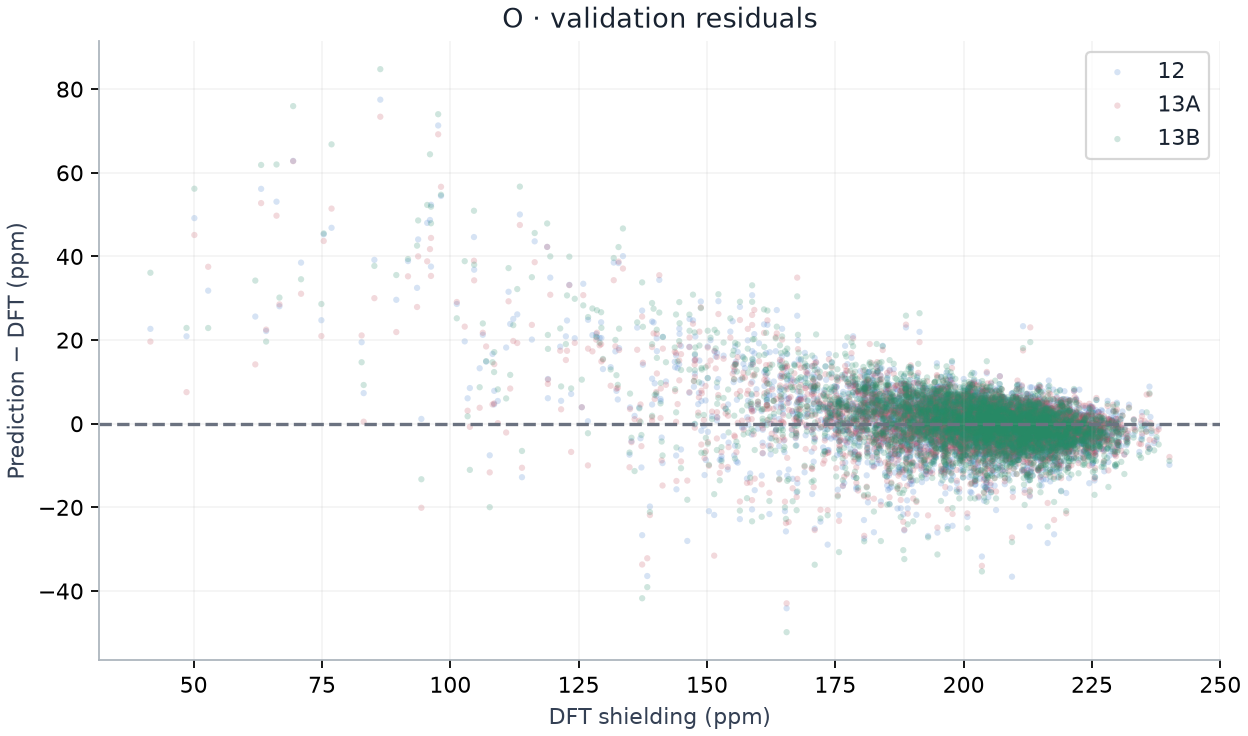

,baseline,comparison,element,delta_low,delta_high
0,12,13A,Si,-5.1407,-4.5007
1,12,13A,O,-0.6468,-0.3633
2,12,13B,Si,-6.0744,-5.5120
3,12,13B,O,0.3709,0.8583
4,13A,13B,Si,-1.1113,-0.8513
5,13A,13B,O,0.8171,1.4204


In [4]:
display(Image(filename=str(data/"residuals-Si.png")))
display(Image(filename=str(data/"residuals-O.png")))
display(pd.read_csv(data/"paired-rmse-changes.csv").round(4))

## Verification and scope

Fresh validation predictions use frozen features only after exact backbone equality was checked across every evaluated model. Full model forwards were cross-checked on validation structures 0, 25 and 49. Training metrics use an existing feature cache whose training-data and source-model hashes were verified; they are diagnostic only. Metrics are aggregated over atoms, with structure-level resampling for the paired RMSE differences (4,000 draws, 95% percentile intervals).

The exported model weights match the selected best checkpoints. Recomputed validation objectives agree with saved checkpoint scores within 0.05%, allowing for CPU/GPU floating-point differences. Best and last checkpoints are reported separately. Inputs were hashed and checked unchanged after evaluation. No training was performed.

These are exploratory validation results on a validation set already used for model selection, not an untouched test-set assessment.
